In [1]:
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import os

In [2]:
# データの読み込み

# https://imarinfr.r-universe.dev/datasets
# chatgptに選定。9.visualFields::vfpwgRetest24d2
dir_data =r"./data/vfpwgRetest24d2.csv"

df_data = pd.read_csv(dir_data)
df_data.head()

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,29,26,27,28,30,25,25,27,31
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,28,29,29,30,31,26,25,28,31
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,28,25,23,28,24,26,26,25
3,1,OD,2008-09-03,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,26,27,26,25,25,27,25,24,26,29
4,1,OD,2008-09-10,00:00:00,53,pwg,0,0.0,0.13,00:00:00,...,28,28,27,25,25,27,25,24,25,26


In [3]:
# 視線データのラベルの確認
print(df_data.columns)

Index(['id', 'eye', 'date', 'time', 'age', 'type', 'fpr', 'fnr', 'fl',
       'duration', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10',
       'l11', 'l12', 'l13', 'l14', 'l15', 'l16', 'l17', 'l18', 'l19', 'l20',
       'l21', 'l22', 'l23', 'l24', 'l25', 'l26', 'l27', 'l28', 'l29', 'l30',
       'l31', 'l32', 'l33', 'l34', 'l35', 'l36', 'l37', 'l38', 'l39', 'l40',
       'l41', 'l42', 'l43', 'l44', 'l45', 'l46', 'l47', 'l48', 'l49', 'l50',
       'l51', 'l52', 'l53', 'l54'],
      dtype='str')


In [4]:
l_coord_id = ['l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10',
       'l11', 'l12', 'l13', 'l14', 'l15', 'l16', 'l17', 'l18', 'l19', 'l20',
       'l21', 'l22', 'l23', 'l24', 'l25', 'l26', 'l27', 'l28', 'l29', 'l30',
       'l31', 'l32', 'l33', 'l34', 'l35', 'l36', 'l37', 'l38', 'l39', 'l40',
       'l41', 'l42', 'l43', 'l44', 'l45', 'l46', 'l47', 'l48', 'l49', 'l50',
       'l51', 'l52', 'l53', 'l54']

In [5]:
# 患者ID一覧の確認
print(df_data["id"].unique())
print(df_data["id"].nunique())

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30]
30


In [6]:
# 患者ごとのメタデータの確認
for i_id in df_data["id"].unique():
    print(
        "patient:", i_id, 
        ", checked num:", len(df_data[df_data["id"]==i_id]), 
        ", eye_side:", df_data[df_data["id"]==i_id]["eye"].unique().tolist(),
        ", age:", df_data[df_data["id"]==i_id]["age"].unique().tolist(),
        ", type:", df_data[df_data["id"]==i_id]["type"].unique().tolist(),
        ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
        )

patient: 1 , checked num: 12 , eye_side: ['OD'] , age: [53] , type: ['pwg'] , FL>0: 6
patient: 2 , checked num: 12 , eye_side: ['OD'] , age: [72] , type: ['pwg'] , FL>0: 2
patient: 3 , checked num: 12 , eye_side: ['OD'] , age: [67] , type: ['pwg'] , FL>0: 3
patient: 4 , checked num: 12 , eye_side: ['OS'] , age: [46] , type: ['pwg'] , FL>0: 7
patient: 5 , checked num: 12 , eye_side: ['OD'] , age: [69] , type: ['pwg'] , FL>0: 2
patient: 6 , checked num: 12 , eye_side: ['OS'] , age: [64] , type: ['pwg'] , FL>0: 1
patient: 7 , checked num: 12 , eye_side: ['OS'] , age: [65, 66] , type: ['pwg'] , FL>0: 12
patient: 8 , checked num: 12 , eye_side: ['OS'] , age: [60] , type: ['pwg'] , FL>0: 6
patient: 9 , checked num: 12 , eye_side: ['OD'] , age: [83] , type: ['pwg'] , FL>0: 3
patient: 10 , checked num: 12 , eye_side: ['OS'] , age: [56] , type: ['pwg'] , FL>0: 11
patient: 11 , checked num: 12 , eye_side: ['OS'] , age: [69] , type: ['pwg'] , FL>0: 4
patient: 12 , checked num: 12 , eye_side: ['OD

/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ", FL>0:", len(df_data[df_data["id"]==i_id][df_data["fl"]>0]),
/tmp/ipykernel_16678/1660759657.py:9: UserWarning: Boolean Series key will be reindexed to match DataFram

In [7]:
# 欠損値の確認
print(df_data.isnull().sum().tolist())

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [8]:
df_data[df_data["id"]==1]

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,29,26,27,28,30,25,25,27,31
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,28,29,29,30,31,26,25,28,31
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,28,25,23,28,24,26,26,25
3,1,OD,2008-09-03,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,26,27,26,25,25,27,25,24,26,29
4,1,OD,2008-09-10,00:00:00,53,pwg,0,0.0,0.13,00:00:00,...,28,28,27,25,25,27,25,24,25,26
5,1,OD,2008-09-17,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,27,28,28,27,25,27,25,21,25,26
6,1,OD,2008-09-24,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,26,26,24,27,24,26,26,25
7,1,OD,2008-10-01,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,30,29,30,29,24,31,27,26,28,30
8,1,OD,2008-10-08,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,26,29,30,29,28,30,29,27,30,31
9,1,OD,2008-10-15,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,28,29,29,30,29,30,22,27,27,30


In [9]:
# 網膜位置データの読み込み
# ノートブック内のp24d2_coordinates.csvは`locmaps.rda`を変換したものらしい。
# https://github.com/cran/visualFields/blob/d4e4c408655d236dd23ff4f748495cfac74bc77a/data/locmaps.rda
# rdataなら元データを読める
# https://stackoverflow.com/questions/75727882/pyreadr-not-working-how-to-import-rdata-file-to-python/75843129

import rdata

locmaps = rdata.parser.parse_file(r"./data/locmaps.rda")
locmaps_conv = rdata.conversion.convert(locmaps)
locmaps_conv

{'locmaps': {np.str_('p24d2'): {np.str_('name'): array(['24-2'], dtype='<U4'),
   np.str_('desc'): array(['The conventional 24-2 location map as used by the Humphrey and Octopus perimeters'],
         dtype='<U81'),
   np.str_('coord'):       x    y
   1    -9   21
   2    -3   21
   3     3   21
   4     9   21
   5   -15   15
   6    -9   15
   7    -3   15
   8     3   15
   9     9   15
   10   15   15
   11  -21    9
   12  -15    9
   13   -9    9
   14   -3    9
   15    3    9
   16    9    9
   17   15    9
   18   21    9
   19  -27    3
   20  -21    3
   21  -15    3
   22   -9    3
   23   -3    3
   24    3    3
   25    9    3
   26   15    3
   27   21    3
   28  -27   -3
   29  -21   -3
   30  -15   -3
   31   -9   -3
   32   -3   -3
   33    3   -3
   34    9   -3
   35   15   -3
   36   21   -3
   37  -21   -9
   38  -15   -9
   39   -9   -9
   40   -3   -9
   41    3   -9
   42    9   -9
   43   15   -9
   44   21   -9
   45  -15  -15
   46   -9  -15
   47   -3  -1

In [10]:
# そのうちのp24d2が今回の対象。ほかは何？
# p24d2
# p24d2fdt
# p24d2f
# p24d2fdtf
# p24d2c
locmaps_conv["locmaps"].keys()

dict_keys([np.str_('p24d2'), np.str_('p30d2'), np.str_('p10d2'), np.str_('p30d1'), np.str_('p24d2fdt'), np.str_('p24d2f'), np.str_('p30d2f'), np.str_('p10d2f'), np.str_('p30d1f'), np.str_('p24d2fdtf'), np.str_('p60d4'), np.str_('pSGNRFL'), np.str_('pPC26'), np.str_('pPeri'), np.str_('p24d2c'), np.str_('g1')])

In [11]:
## メタデータを確認。今回は一般的なデータを扱うため。
for i in locmaps_conv["locmaps"].keys():
    print("{}: {}".format(i,locmaps_conv["locmaps"][i][np.str_('desc')][0]))

p24d2: The conventional 24-2 location map as used by the Humphrey and Octopus perimeters
p30d2: The conventional 30-2 location map as used by the Humphrey and Octopus perimeters
p10d2: The conventional 10-2 location map as used by the Humphrey and Octopus perimeters
p30d1: The 30-1 location map
p24d2fdt: FDT version of the 24-2 location map as used by the Matrix perimeter
p24d2f: The conventional 24-2 location map as used by the Humphrey and Octopus perimeters with fixation point
p30d2f: The conventional 30-2 location map as used by the Humphrey and Octopus perimeters with fixation point
p10d2f: The conventional 10-2 location map as used by the Humphrey and Octopus perimeters with fixation point
p30d1f: The 30-1 location map with fixation point
p24d2fdtf: FDT version of the 24-2 location map as used by the Matrix perimeter
p60d4: The 60-4 location map
pSGNRFL: Irregular location map used for contrast sensitivity perimetry based on the RNFL-bundle average path
pPC26: A map of 64 locatio

- **`p24d2`**：HumphreyおよびOctopus視野計で使用される、従来型の24-2測定点配置。
- **`p30d2`**：HumphreyおよびOctopus視野計で使用される、従来型の30-2測定点配置。
- **`p10d2`**：HumphreyおよびOctopus視野計で使用される、従来型の10-2測定点配置。
- **`p30d1`**：30-1測定点配置。
- **`p24d2fdt`**：Matrix視野計で使用される、FDT（周波数倍増技術）方式の24-2測定点配置。
- **`p24d2f`**：HumphreyおよびOctopus視野計で使用される、従来型の24-2測定点配置に固視点を追加したもの。
- **`p30d2f`**：HumphreyおよびOctopus視野計で使用される、従来型の30-2測定点配置に固視点を追加したもの。
- **`p10d2f`**：HumphreyおよびOctopus視野計で使用される、従来型の10-2測定点配置に固視点を追加したもの。
- **`p30d1f`**：30-1測定点配置に固視点を追加したもの。
- **`p24d2fdtf`**：Matrix視野計で使用される、FDT方式の24-2測定点配置。
- **`p60d4`**：60-4測定点配置。
- **`pSGNRFL`**：網膜神経線維層（RNFL）の神経線維束の平均走行に基づく、コントラスト感度視野検査に使用される不規則な測定点配置。
- **`pPC26`**：中心視野26度以内に64個の測定点を配置したマップ。
- **`pPeri`**：視野の中心から26〜81度の周辺視野に64個の測定点を配置したマップ。
- **`p24d2c`**：Humphrey視野計で使用される24-2C測定点配置。
- **`g1`**：Octopus視野計で使用されるG1測定点配置。

| 用語・略語 | 正式名称・意味 |
|---|---|
| Location map | 測定点配置。視野検査で刺激を提示する位置を定義したもの |
| Humphrey | Humphrey Field Analyzer（HFA）。ハンフリー視野計 |
| Octopus | Octopus Perimeter。オクトパス視野計 |
| FDT | Frequency Doubling Technology。周波数倍増技術 |
| Matrix | Humphrey Matrix。FDTを利用した視野計 |
| Fixation point | 固視点。被検者が検査中に注視する位置 |
| RNFL | Retinal Nerve Fiber Layer。網膜神経線維層 |
| RNFL bundle | 網膜神経線維束 |
| Contrast sensitivity perimetry | コントラスト感度視野検査 |
| Peripheral visual field | 周辺視野 |

In [12]:
# https://imarinfr.r-universe.dev/visualFieldsの`locmaps`でよかったのでは？
print(locmaps_conv["locmaps"][np.str_('p24d2')].keys())
print(locmaps_conv["locmaps"][np.str_('p24d2')])

dict_keys([np.str_('name'), np.str_('desc'), np.str_('coord'), np.str_('bs')])
{np.str_('name'): array(['24-2'], dtype='<U4'), np.str_('desc'): array(['The conventional 24-2 location map as used by the Humphrey and Octopus perimeters'],
      dtype='<U81'), np.str_('coord'):       x    y
1    -9   21
2    -3   21
3     3   21
4     9   21
5   -15   15
6    -9   15
7    -3   15
8     3   15
9     9   15
10   15   15
11  -21    9
12  -15    9
13   -9    9
14   -3    9
15    3    9
16    9    9
17   15    9
18   21    9
19  -27    3
20  -21    3
21  -15    3
22   -9    3
23   -3    3
24    3    3
25    9    3
26   15    3
27   21    3
28  -27   -3
29  -21   -3
30  -15   -3
31   -9   -3
32   -3   -3
33    3   -3
34    9   -3
35   15   -3
36   21   -3
37  -21   -9
38  -15   -9
39   -9   -9
40   -3   -9
41    3   -9
42    9   -9
43   15   -9
44   21   -9
45  -15  -15
46   -9  -15
47   -3  -15
48    3  -15
49    9  -15
50   15  -15
51   -9  -21
52   -3  -21
53    3  -21
54    9  -21, np.str_(

In [13]:
display(df_data)

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,29,26,27,28,30,25,25,27,31
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,28,29,29,30,31,26,25,28,31
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,28,25,23,28,24,26,26,25
3,1,OD,2008-09-03,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,26,27,26,25,25,27,25,24,26,29
4,1,OD,2008-09-10,00:00:00,53,pwg,0,0.0,0.13,00:00:00,...,28,28,27,25,25,27,25,24,25,26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,30,OS,2009-05-08,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,22,27,28,29,29,28,24,25,26,25
356,30,OS,2009-05-15,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,22,26,30,28,30,30,22,27,26,23
357,30,OS,2009-05-25,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,22,29,30,26,28,28,24,26,25,23
358,30,OS,2009-05-29,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,22,27,30,30,30,27,23,25,26,27


In [14]:
# 可視化のための最小値と最大値の設定
data_max = df_data[l_coord_id].max().max()
data_min = df_data[l_coord_id].min().min()
print(data_max, data_min)

43 0


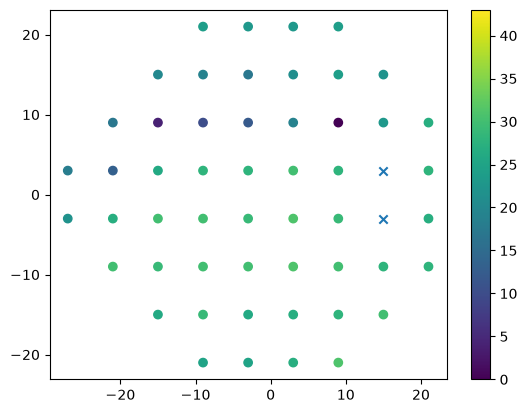

In [15]:
# 1被験者のデータの可視化
coord = locmaps_conv["locmaps"][np.str_('p24d2')][np.str_('coord')]
bs_pos = locmaps_conv["locmaps"][np.str_('p24d2')][np.str_('bs')]
bs_pos_int_0org = [int(i)-1 for i in bs_pos]
# print(coord)
# print(bs_pos)
# print(bs_pos_int_0org)

coord_bs = [f"l{int(i)}" for i in bs_pos]
# print(coord_bs)
l_coord_id_wo_bs = [i for i in l_coord_id if not i in coord_bs]
# print(l_coord_id_wo_bs)

# display(coord.head())

# https://pythondatascience.plavox.info/matplotlib/%E6%95%A3%E5%B8%83%E5%9B%B3
# for i_id in ["id"]

data_pat = df_data.iloc[0][l_coord_id_wo_bs]

l_x_pos = []
l_y_pos = []
l_x_pos_bs = []
l_y_pos_bs = []
for i_id in range(len(coord)):
    # print(coord.iloc[i_id])
    x_pos, y_pos = coord.iloc[i_id]
    if i_id in bs_pos_int_0org:
        l_x_pos_bs.append(x_pos)
        l_y_pos_bs.append(y_pos)
    else:
        l_x_pos.append(x_pos)
        l_y_pos.append(y_pos)
    # print(f"l{i_id+1}")

plt.scatter(l_x_pos, l_y_pos, c=data_pat, vmax=data_max, vmin=data_min)
plt.colorbar()
plt.scatter(l_x_pos_bs, l_y_pos_bs, marker="x")

plt.show()

In [16]:
# 各被験者データの可視化
# 左目に左右反転が適用できてないので書き直す。
def save_each_patient(df_data_single, dir_save, name_suffix="", name_base="_patient"):
    
    data_pat = df_data_single[l_coord_id_wo_bs]


    plt.scatter(l_x_pos, l_y_pos, c=data_pat, vmax=data_max, vmin=data_min)
    plt.colorbar()
    plt.scatter(l_x_pos_bs, l_y_pos_bs, marker="x")

    dir_save_fig = os.path.join(dir_save, f"{name_suffix}{name_base}.png")
    plt.savefig(dir_save_fig)
    # plt.show()
    plt.close()

dir_save = r"./figs"
os.makedirs(dir_save, exist_ok=True)

# for i_pat in range(len(df_data.index)):
#     data_pat = df_data.iloc[i_pat][l_coord_id_wo_bs]
#     save_each_patient(data_pat, dir_save, name_suffix=f"l{i_pat+1}", name_base="_patient")

for i_id in df_data["id"].unique():
    # print(i_id)
    data_each_pat = df_data[df_data["id"]==i_id]
    data_each_pat["date"] = pd.to_datetime(data_each_pat["date"])
    data_each_pat["date_exp"] = data_each_pat["date"].dt.strftime("%Y-%m-%d")
    data_each_pat = data_each_pat.sort_values("date")

    for i_exp in range(len(data_each_pat.index)):
        data_each_pat_single = data_each_pat.iloc[i_exp]
        # display(data_each_pat_single)
        s_id = f"l{i_id}"
        s_eye = data_each_pat_single["eye"]
        s_date = data_each_pat_single["date_exp"]
        s_age = data_each_pat_single["age"]
        s_exp = "exp{:02}".format(i_exp+1)
        name_suffix = f"{s_id}_{s_eye}_{s_exp}_{s_date}_{s_age}"
        # print(name_suffix)

        # save_each_patient(data_each_pat_single, dir_save, name_suffix=name_suffix)

In [17]:
# 日付データの変換
df_data["date"] = pd.to_datetime(df_data["date"])
df_data["date_exp"] = df_data["date"].dt.strftime("%Y-%m-%d")
df_data = df_data.sort_values(["id", "date"])
df_data

# for i_id in df_data["id"].unique():
#     # print(i_id)
#     data_each_pat = df_data[df_data["id"]==i_id]
#     data_each_pat["date"] = pd.to_datetime(data_each_pat["date"])
#     data_each_pat["date_exp"] = data_each_pat["date"].dt.strftime("%Y-%m-%d")
#     data_each_pat = data_each_pat.sort_values("date")

# for i_id in df_data["id"].unique():
#     data_each_pat = df_data[df_data["id"]==i_id]
#     for i_exp in range(len(data_each_pat.index)):
#         data_each_pat_single = data_each_pat.iloc[i_exp]
#         # display(data_each_pat_single)
#         s_id = f"l{i_id}"
#         s_eye = data_each_pat_single["eye"]
#         s_date = data_each_pat_single["date_exp"]
#         s_age = data_each_pat_single["age"]
#         s_exp = "exp{:02}".format(i_exp+1)
#         name_suffix = f"{s_id}_{s_eye}_{s_exp}_{s_date}_{s_age}"
#         # print(name_suffix)

#         save_each_patient(data_each_pat_single, dir_save, name_suffix=name_suffix)

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l46,l47,l48,l49,l50,l51,l52,l53,l54,date_exp
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,29,26,27,28,30,25,25,27,31,2008-08-13
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,29,29,30,31,26,25,28,31,2008-08-20
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,27,28,25,23,28,24,26,26,25,2008-08-27
3,1,OD,2008-09-03,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,27,26,25,25,27,25,24,26,29,2008-09-03
4,1,OD,2008-09-10,00:00:00,53,pwg,0,0.0,0.13,00:00:00,...,28,27,25,25,27,25,24,25,26,2008-09-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,30,OS,2009-05-08,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,27,28,29,29,28,24,25,26,25,2009-05-08
356,30,OS,2009-05-15,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,26,30,28,30,30,22,27,26,23,2009-05-15
357,30,OS,2009-05-25,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,29,30,26,28,28,24,26,25,23,2009-05-25
358,30,OS,2009-05-29,00:00:00,68,pwg,0,0.0,0.00,00:00:00,...,27,30,30,30,27,23,25,26,27,2009-05-29


In [18]:
# 各被験者データの保存
# 左目に左右反転を追加
def save_each_patient(df_data_single, dir_save, name_suffix="", name_base="_patient"):
    
    data_pat = df_data_single[l_coord_id_wo_bs]
    if df_data_single["eye"] == "OS":
        # print("warning!")
        l_x_pos_LR = np.array(l_x_pos)*-1
        l_x_pos_bs_LR = np.array(l_x_pos_bs)*-1
    else:
        l_x_pos_LR = l_x_pos
        l_x_pos_bs_LR = l_x_pos_bs

    plt.scatter(l_x_pos_LR, l_y_pos, c=data_pat, vmax=data_max, vmin=data_min)
    plt.colorbar()
    plt.scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")

    dir_save_fig = os.path.join(dir_save, f"{name_suffix}{name_base}.png")
    plt.savefig(dir_save_fig)
    # plt.show()
    plt.close()

dir_save = r"./figs"
os.makedirs(dir_save, exist_ok=True)

# for i_pat in range(len(df_data.index)):
#     data_pat = df_data.iloc[i_pat][l_coord_id_wo_bs]
#     save_each_patient(data_pat, dir_save, name_suffix=f"l{i_pat+1}", name_base="_patient")

for i_id in df_data["id"].unique():
    # print(i_id)
    data_each_pat = df_data[df_data["id"]==i_id]

    for i_exp in range(len(data_each_pat.index)):
        data_each_pat_single = data_each_pat.iloc[i_exp]
        # display(data_each_pat_single)
        s_id = f"l{i_id}"
        s_eye = data_each_pat_single["eye"]
        s_date = data_each_pat_single["date_exp"]
        s_age = data_each_pat_single["age"]
        s_exp = "exp{:02}".format(i_exp+1)
        name_suffix = f"{s_id}_{s_eye}_{s_exp}_{s_date}_{s_age}"
        # print(name_suffix)

        # save_each_patient(data_each_pat_single, dir_save, name_suffix=name_suffix)

0     24.288462
1     26.500000
2     24.615385
3     25.269231
4     25.596154
5     23.942308
6     24.384615
7     26.346154
8     25.711538
9     25.230769
10    25.019231
11    25.480769
dtype: float64

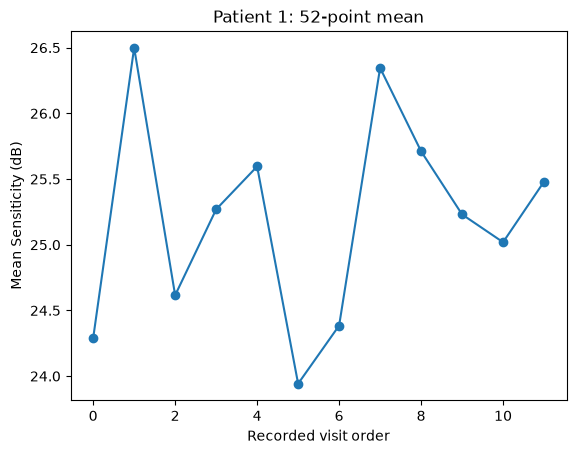

In [19]:
# 感度平均の推移を可視化
for i_id in df_data["id"].unique():
    data_each_pat = df_data[df_data["id"]==i_id]
    display(data_each_pat[l_coord_id_wo_bs].mean(axis=1))
    plt.plot(data_each_pat[l_coord_id_wo_bs].mean(axis=1), marker="o")
    plt.xlabel("Recorded visit order")
    plt.ylabel("Mean Sensiticity (dB)")
    plt.title(f"Patient {i_id}: 52-point mean")
    plt.show()
    # df_data[].max().max()
    
    break

0     24.288462
1     26.500000
2     24.615385
3     25.269231
4     25.596154
5     23.942308
6     24.384615
7     26.346154
8     25.711538
9     25.230769
10    25.019231
11    25.480769
dtype: float64

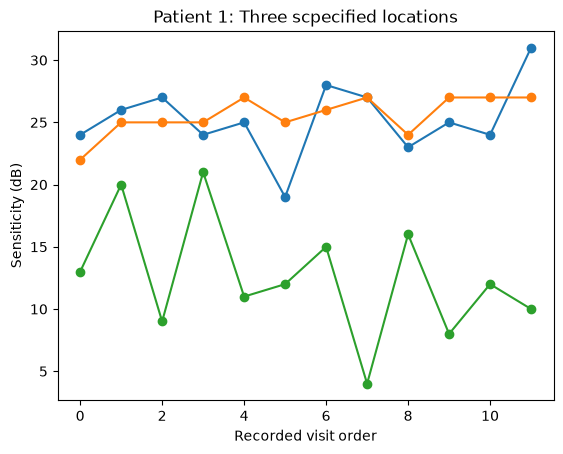

In [20]:
# 視野内の3点を可視化
for i_id in df_data["id"].unique():
    data_each_pat = df_data[df_data["id"]==i_id]
    display(data_each_pat[l_coord_id_wo_bs].mean(axis=1))
    for point in ['l1','l10','l20']:
        plt.plot(data_each_pat[point], marker="o")
    plt.xlabel("Recorded visit order")
    plt.ylabel("Sensiticity (dB)")
    plt.title(f"Patient {i_id}: Three scpecified locations")
    plt.show()
    # df_data[].max().max()
    
    break

In [21]:
# 訪問回数と次の訪問までの日にちを被験者と目ごとに算出
df_data["visit"] = df_data.groupby(["id", "eye"]).cumcount()+1
df_data["gap_days"] = df_data.groupby(["id", "eye"])["date"].diff().dt.days
df_data["gap_days"]

0       NaN
1       7.0
2       7.0
3       7.0
4       7.0
       ... 
355     7.0
356     7.0
357    10.0
358     4.0
359     7.0
Name: gap_days, Length: 360, dtype: float64

In [22]:
## データセット分割。被験者IDで分割し、訓練とテストのデータに同被験者データが混ざらないように設定

TEST_NUM = 9
TRAIN_NUM = len(df_data["id"].unique()) - TEST_NUM
print(TRAIN_NUM)
# l_isTEST = [True]*TEST_NUM + [False]*TARGET_NUM
# random.shuffle(l_isTEST)

from sklearn.model_selection import train_test_split
X_train_id, X_test_id = train_test_split(
    df_data["id"].unique(), 
    test_size = TEST_NUM,
    random_state=42
    )
print(X_train_id, X_test_id)

21
[ 1  5 17  6 14 12 23  2  3 26  4 22 27 19 30 21  8 11 15 20  7] [28 16 24 18  9 10 29 25 13]


In [23]:
HISTORY = 3

histories     = []
targets      = []
metadata    = []
for (pid, eye), g_data in df_data.groupby(["id", "eye"]):
    g_data = g_data.sort_values("date").reset_index(drop=True)
    values = g_data[l_coord_id_wo_bs].to_numpy(dtype=float)

    # display(g_data)
    # display(values)
    for i in range(HISTORY,len(g_data)):
        # print(i-HISTORY, i)
        data_history = values[i-HISTORY:i]
        histories.append(data_history)
        # display(data_history)
        data_target = values[i]
        targets.append(data_target)
        # display(data_target)
        metadata.append({
            "id":int(pid),
            "eye":eye,
            "target_visit": int(g_data.loc[i, "visit"]),
            "history_last_date": g_data.loc[i-1, "date"],
            "target_date":g_data.loc[i, "date"],
            "gap_days": float(g_data.loc[i, "gap_days"]),
            "target_fl": float(g_data.loc[i, "fl"]),
        })

history = np.stack(histories)
Y  = np.stack(targets)
meta = pd.DataFrame(metadata)

mean3 = history.mean(axis=1)
print(mean3.shape)
last = history[:,-1,:]

# 今回は「3回分の平均と、直前の測定値が平均とどれだけズレているかが重要ではないか」という仮説のチュートリアルのため
X = np.concatenate([mean3, last-mean3], axis=1)

is_train = meta["id"].isin(X_train_id)
is_test = meta["id"].isin(X_test_id)
display(is_train)

(270, 52)


0      True
1      True
2      True
3      True
4      True
       ... 
265    True
266    True
267    True
268    True
269    True
Name: id, Length: 270, dtype: bool

In [24]:
X_train = X[is_train]
X_test = X[is_test]
Y_train = Y[is_train]
Y_test = Y[is_test]

In [25]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=1.0)
model.fit(X_train, Y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [26]:
print(X_train.shape)
print(X_test.shape)

(189, 104)
(81, 104)


In [27]:
prediction = model.predict(X_test)
# print(prediction)
# print(Y_test)


In [77]:
# from sklearn.preprocessing import StandardScaler
# from sklearn.pipeline import make_pipeline
# from sklearn.model_selection import GridSearchCV

# model_grid = make_pipeline(
#     StandardScaler(),
#     Ridge()
# )
# lambdas = np.logspace(-4, 4, 50)

# search = GridSearchCV(
#     model_grid,
#     param_grid={"ridge__lpha":lambdas},
#     cv=5,
#     scoring="neg_mean_squared_error",
# )
# model_grid.fit(X_train, Y_train)

# prediction_grid = model_grid.predict(X_test)

# CharGPTでの修正
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold

model_grid = make_pipeline(
    StandardScaler(),
    Ridge()
)
lambdas = np.logspace(-4, 4, 50)

search = GridSearchCV(
    model_grid,
    param_grid={"ridge__alpha":lambdas},
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_squared_error",
)

training_group = meta.loc[is_train, "id"].to_numpy()
display(training_group)

search.fit(X_train, Y_train, groups=training_group)

print("最適なα: ", search.best_params_)
print("λ: ", search.best_params_["ridge__alpha"]/X_test.shape[1])

prediction_grid = search.predict(X_test)

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,
        4,  4,  5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,
        6,  6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8, 11, 11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12,
       12, 12, 12, 12, 12, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 17, 17, 17, 17, 17, 17, 17, 17, 17, 19, 19,
       19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20, 20, 20, 20, 20, 20, 21,
       21, 21, 21, 21, 21, 21, 21, 21, 22, 22, 22, 22, 22, 22, 22, 22, 22,
       23, 23, 23, 23, 23, 23, 23, 23, 23, 26, 26, 26, 26, 26, 26, 26, 26,
       26, 27, 27, 27, 27, 27, 27, 27, 27, 27, 30, 30, 30, 30, 30, 30, 30,
       30, 30])

最適なα:  {'ridge__alpha': np.float64(159.98587196060572)}
λ:  1.5383256919289012


αは大きいが104点なのでlambdasの範囲に入る。

In [29]:
# CharGPT提案の正則化とネガティブの値とMAE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

for alpha in [1, 10, 160, 1000]:

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X_train, Y_train)

    pred = model.predict(X_test)

    print(
        f"alpha={alpha:4}",
        f"negative={(pred < 0).sum():3}",
        f"min={pred.min():.3f}",
        f"MAE={np.abs(pred - Y_test).mean():.3f}"
    )
# 負の予測値が発生した位置を調べるのは必要

alpha=   1 negative= 31 min=-54.648 MAE=4.801
alpha=  10 negative= 27 min=-21.298 MAE=3.524
alpha= 160 negative=  1 min=-0.624 MAE=2.807
alpha=1000 negative=  0 min=8.223 MAE=2.887


In [30]:
preds = {
    "last":last[is_test],
    "mean3":mean3[is_test],
    "ridge":prediction_grid,
    "ridge_single":prediction,
}
print("last negative:", (preds["last"]<0).sum())
print("mean3 negative:", (preds["mean3"]<0).sum())
print("ridge negative:", (preds["ridge"]<0).sum())
print("ridge_single negative:", (preds["ridge_single"]<0).sum())

last negative: 0
mean3 negative: 0
ridge negative: 1
ridge_single negative: 63


In [31]:
# MAEは絶対値の差の平均
# これは全体で見る
for name, pred_each in preds.items():
    absolute_error = np.abs(pred_each - Y_test)
    mae = absolute_error.mean()
    print("{} : {:.5}".format(name, mae))

last : 2.103
mean3 : 1.7807
ridge : 2.8067
ridge_single : 6.0899


In [32]:
# 予測が9x9
preds["ridge"].shape

(81, 52)

In [33]:
meta_test = meta[is_test].copy()
meta_test = meta_test.reset_index(drop=True)
meta_test

,id,eye,target_visit,history_last_date,target_date,gap_days,target_fl
0,9,OD,4,2009-01-28,2009-02-05,8.0,0.00
1,9,OD,5,2009-02-05,2009-02-11,6.0,0.00
2,9,OD,6,2009-02-11,2009-02-18,7.0,0.00
3,9,OD,7,2009-02-18,2009-02-25,7.0,0.00
4,9,OD,8,2009-02-25,2009-03-05,8.0,0.00
...,...,...,...,...,...,...,...
76,29,OD,8,2009-04-15,2009-04-22,7.0,0.13
77,29,OD,9,2009-04-22,2009-04-29,7.0,0.06
78,29,OD,10,2009-04-29,2009-05-06,7.0,0.13
79,29,OD,11,2009-05-06,2009-05-13,7.0,0.13


In [34]:
# 患者別のMAE
def calc_mae_per_pati(pred_data, y_test_data):
    absolute_error = np.abs(pred_data - y_test_data)
    mae_visit = absolute_error.mean(axis=1)
    mae = mae_visit.mean()
    return mae

patient_mae = pd.DataFrame(
    index=meta_test["id"].unique(),
    columns=["last","mean3","ridge","ridge_single"]
    ) 
patient_mae.index.name = "id"
patient_mae.columns
# display(patient_mae)

for i_id in meta_test["id"].unique():
    # df_result_tmp = pd.DataFrame() 
    id_range = meta_test[meta_test["id"]==i_id].index
    # print(id_range)

    # display(preds["last"][id_range].shape)
    # display(Y_test[id_range].shape)
    # display(np.abs(preds["last"][id_range] - Y_test[id_range]).mean(axis=1).shape)
    # display(np.abs(preds["last"][id_range] - Y_test[id_range]).mean(axis=1).mean())

    # patient_mae.iloc[i_id] = ({
    #     "last": calc_mae_per_pati(preds["last"][id_range], Y_test[id_range]),
    #     "mean3": calc_mae_per_pati(preds["mean3"][id_range], Y_test[id_range]),
    #     "ridge": calc_mae_per_pati(preds["ridge"][id_range], Y_test[id_range]),
    # }) 

    patient_mae.loc[i_id] = [
        calc_mae_per_pati(preds["last"][id_range], Y_test[id_range]),
        calc_mae_per_pati(preds["mean3"][id_range], Y_test[id_range]),
        calc_mae_per_pati(preds["ridge"][id_range], Y_test[id_range]),
        calc_mae_per_pati(preds["ridge_single"][id_range], Y_test[id_range]),
    ]
    # mae_each = calc_mae(preds["ridge_single"][id_range], Y_test[id_range])
    # display(df_result_tmp)
    # break

# 値が異なるのは被験者の選定が異なるため
display(patient_mae)

# for name, pred_each in preds.items():
#     print((pred_each<0).sum())

metrics = pd.DataFrame({
    "patient_macro_MAE_dB":patient_mae.mean(),
    "worse_patient_MAE_dB":patient_mae.max(),
    "negatibe_prediction":{name: int((pred_each<0).sum()) for name, pred_each in preds.items()},
})


display(metrics)

,last,mean3,ridge,ridge_single
id,,,,
9,1.621795,1.418803,1.560612,2.364652
10,1.837607,1.55698,1.894212,4.572938
13,2.702991,2.282051,3.05491,5.713969
16,1.376068,1.116097,1.361135,2.484645
18,2.446581,2.10755,4.615676,10.688969
24,2.777778,2.425926,6.175672,16.688715
25,1.621795,1.336182,1.379022,2.215688
28,1.831197,1.501425,1.723277,2.869785
29,2.711538,2.281339,3.49559,7.209955


,patient_macro_MAE_dB,worse_patient_MAE_dB,negatibe_prediction
last,2.103039,2.777778,0
mean3,1.780706,2.425926,0
ridge,2.806678,6.175672,1
ridge_single,6.089924,16.688715,63


In [35]:
display(patient_mae)
display(metrics)

,last,mean3,ridge,ridge_single
id,,,,
9,1.621795,1.418803,1.560612,2.364652
10,1.837607,1.55698,1.894212,4.572938
13,2.702991,2.282051,3.05491,5.713969
16,1.376068,1.116097,1.361135,2.484645
18,2.446581,2.10755,4.615676,10.688969
24,2.777778,2.425926,6.175672,16.688715
25,1.621795,1.336182,1.379022,2.215688
28,1.831197,1.501425,1.723277,2.869785
29,2.711538,2.281339,3.49559,7.209955


,patient_macro_MAE_dB,worse_patient_MAE_dB,negatibe_prediction
last,2.103039,2.777778,0
mean3,1.780706,2.425926,0
ridge,2.806678,6.175672,1
ridge_single,6.089924,16.688715,63


[]

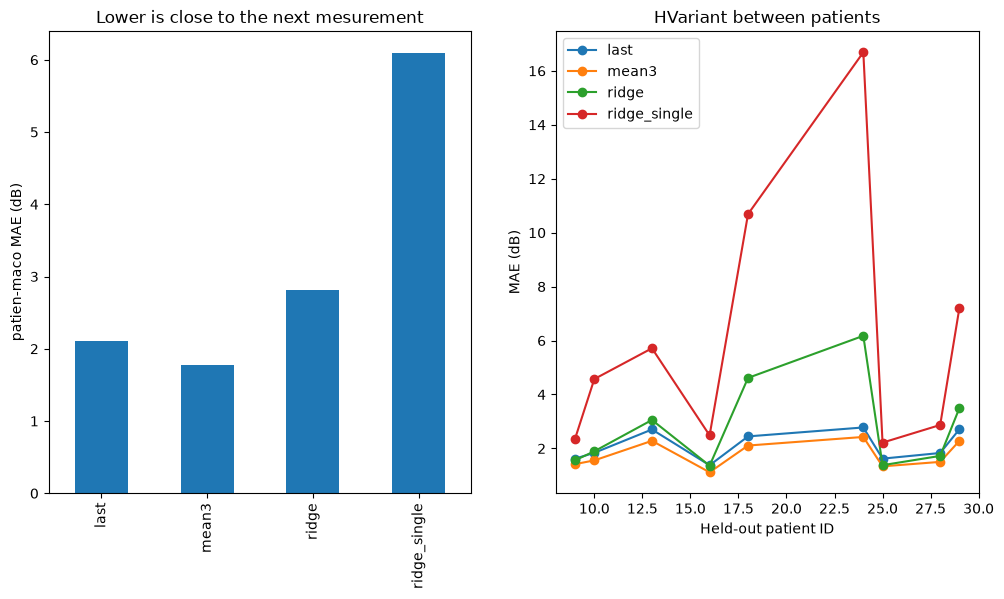

In [36]:
fig = plt.figure(figsize=(12,6))
axes = fig.subplots(1,2)
metrics["patient_macro_MAE_dB"].plot.bar(ax=axes[0])
axes[0].set_ylabel("patien-maco MAE (dB)")
# axes[0].set_xlabel("Held-out patient ID")
axes[0].set_title("Lower is close to the next mesurement")
patient_mae.plot(ax=axes[1], marker="o")
axes[1].set_ylabel("MAE (dB)")
axes[1].set_xlabel("Held-out patient ID")
axes[1].set_title("HVariant between patients")
plt.plot()

In [37]:
print(Y_test.shape)
# (81, 52)

print(preds["ridge"].shape)
# (81, 52)

d_wise_point_mae = {}
l_type = ["last",	"mean3",	"ridge"]
for i_type in l_type:
    d_wise_point_mae[i_type]  = np.abs(preds[i_type] - Y_test).mean(axis=0)
# point_mae = np.abs(preds["ridge"] - Y_test).mean(axis=0)
# print(point_mae.shape)

(81, 52)
(81, 52)


In [38]:
l_max = []
l_min = []
for i_type in l_type:
    l_max.append(max(d_wise_point_mae[i_type]))
    l_min.append(min(d_wise_point_mae[i_type]))
data_max = max(l_max)
data_min = max(l_min)

0 last
1 mean3
2 ridge


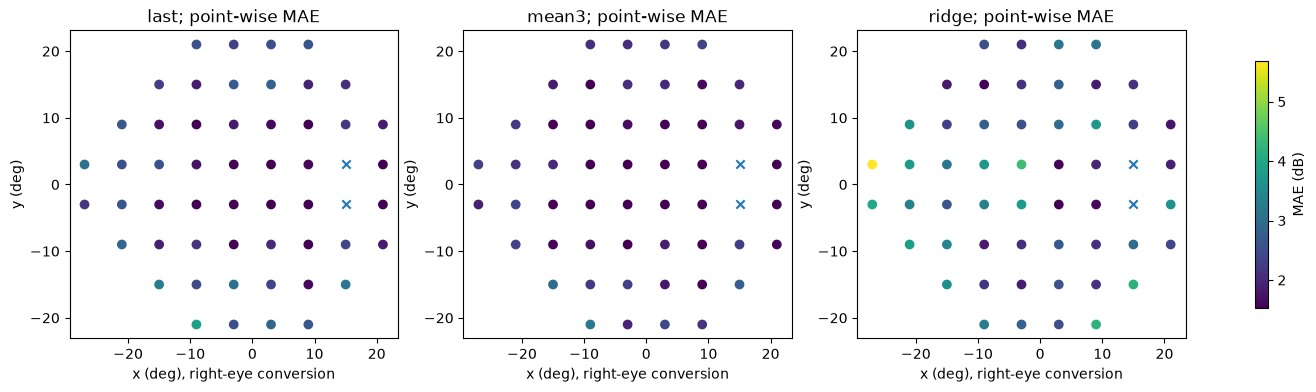

In [39]:
# data_pat = point_mae[l_coord_id_wo_bs]

fig = plt.figure(figsize=(18,4))
axes = fig.subplots(1,3)
l_x_pos_LR = l_x_pos
l_x_pos_bs_LR = l_x_pos_bs

for i, (i_type, data_mae) in enumerate(d_wise_point_mae.items()):
    print(i, i_type)

    sc = axes[i].scatter(l_x_pos_LR, l_y_pos, c=data_mae, vmax=data_max, vmin=data_min)
    # axes[i].colorbar()
    axes[i].scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")
    axes[i].set(title=f"{i_type}; point-wise MAE", xlabel="x (deg), right-eye conversion", ylabel="y (deg)")

# dir_save_fig = os.path.join(dir_save, f"{name_suffix}{name_base}.png")
# plt.savefig(dir_save_fig)
# plt.colorbar()
fig.colorbar(sc, ax=axes, label='MAE (dB)', shrink=.8)
plt.show()
# plt.close()

# 周辺視野ほど予測が外れやすい？

In [40]:
for i, (i_type, data_mae) in enumerate(d_wise_point_mae.items()):
    print(i, i_type)

0 last
1 mean3
2 ridge


In [41]:
import itertools

for i in itertools.combinations(["last",	"mean3",	"ridge"], 2):
    print(i)

('last', 'mean3')
('last', 'ridge')
('mean3', 'ridge')


In [42]:
# paired boootstrapという手法
# 2つの手法の結果の比較を行う
rng = np.random.default_rng(1)

l_datas_boot = []
for i_type in itertools.combinations(["last",	"mean3",	"ridge"], 2): # = ["last",	"mean3",	"ridge"]
    # print(i, l_type[i], l_type[i-1])
    patient_mae_ind = patient_mae.reset_index(drop=0)
    difference = (patient_mae_ind[i_type[0]] - patient_mae_ind[i_type[1]]).to_numpy()
    print(difference.shape)
    idx = rng.integers(
        0, 
        len(difference),
        size=(5000, len(difference)),
    )
    print(idx.shape)
    print(idx[0])
    boot = difference[idx].mean(axis=1)

    lo, ho = np.quantile(boot, [0.025, 0.975])

    print(i_type[0], i_type[1], difference.mean(), lo, ho, difference.shape)
    d_datas = {}
    d_datas["comparison"] = f"{i_type[0]}-{i_type[1]}"
    d_datas["mean_difference_dB"] = difference.mean()
    d_datas["ci_2.5%"] = lo
    d_datas["ci_97.5%"] = ho
    d_datas["patients"] = len(difference)
    # print(d_datas)

    l_datas_boot.append(d_datas)

ci = pd.DataFrame(l_datas_boot)
ci
    


(9,)
(5000, 9)
[4 4 6 8 0 1 7 8 2]
last mean3 0.32233301677746123 0.27738010446343786 0.3674481639759415 (9,)
(9,)
(5000, 9)
[2 6 6 6 4 6 8 3 8]
last ridge -0.7036394844851653 -1.542702501080213 -0.028280469334688092 (9,)
(9,)
(5000, 9)
[4 5 2 4 5 7 8 8 5]
mean3 ridge -1.0259725012626264 -1.8956134955553905 -0.3209570872333451 (9,)


,comparison,mean_difference_dB,ci_2.5%,ci_97.5%,patients
0,last-mean3,0.322333,0.277380,0.367448,9
1,last-ridge,-0.703639,-1.542703,-0.028280,9
2,mean3-ridge,-1.025973,-1.895613,-0.320957,9


In [43]:
# paired boootstrapという手法
# 2つの手法の結果の比較を行う
# 多重比較なので補正が必要。Bonferroni補正。
rng = np.random.default_rng(1)

l_type_labels = ["last",	"mean3",	"ridge"]
l_datas_boot = []

for i_type in itertools.combinations(l_type_labels, 2):
    print(i_type)
    # maeの差を群間で見る
    difference = (patient_mae[i_type[0]]-patient_mae[i_type[1]]).to_numpy()
    # maeの差が実際にどれくらいあるかをみるために平均を出す。
    # これ無しで信頼区間だけ見ていたら？
    diff_mean = difference.mean()
    diff_std = difference.std()
    print("diff_mean, diff_std", diff_mean, diff_std)


    # bootstrapの手順
    # 復元抽出
    idx = rng.integers(
        0,
        len(difference),
        size=(5000, len(difference)),
    )
    # print(difference[idx].shape)
    boot = difference[idx].mean(axis=1)
    # print(boot.shape)

    boot_mean = boot.mean()
    boot_se = boot.std()/np.sqrt(len(boot)) 
    print("boot_mean, boot_std", boot_mean, boot_se)
    
    # 信頼区間を作る
    # lo, hi = np.quantile(boot, [0.025, 0.975])
    # Bonferroni補正
    # 有意水準を比較回数で割ったものを有意水準として使用
    alpha = 0.05/len([i for i in itertools.combinations(l_type_labels, 2)])
    # print(alpha, [alpha/2, 1-(alpha/2)])
    lo, hi = np.quantile(boot, [alpha/2, 1-(alpha/2)])

    # データ保存
    d_datas = {}
    d_datas["compared"] =  f"{i_type[0]}-{i_type[1]}"
    d_datas["mean_difference_dB"] =  diff_mean 
    d_datas["low {:.4}".format(alpha/2)] = lo
    d_datas["high {:.4}".format(1-(alpha/2))] = hi
    d_datas["num_patients"] = len(difference)

    l_datas_boot.append(d_datas)

# 表にする
ci = pd.DataFrame(l_datas_boot)
ci
    


('last', 'mean3')
diff_mean, diff_std 0.32233301677746123 0.0697481497117445
boot_mean, boot_std 0.32180292814181766 0.00032898965762498714
('last', 'ridge')
diff_mean, diff_std -0.7036394844851653 1.1837332892557217
boot_mean, boot_std -0.7080906304244419 0.005514644266787821
('mean3', 'ridge')
diff_mean, diff_std -1.0259725012626264 1.2108016199860219
boot_mean, boot_std -1.0264023307122192 0.00571930903008847


,compared,mean_difference_dB,low 0.008333,high 0.9917,num_patients
0,last-mean3,0.322333,0.268381,0.377891,9
1,last-ridge,-0.703639,-1.761403,0.033613,9
2,mean3-ridge,-1.025973,-2.124628,-0.255731,9


In [44]:
# t検定も実施
from scipy import stats

l_datas_ttest = []
for i_type in itertools.combinations(l_type_labels, 2):
    # print(i_type)
    
    difference = (patient_mae[i_type[0]]-patient_mae[i_type[1]]).to_numpy(dtype=float)
    # 同患者内
    result = stats.ttest_1samp(difference, popmean=0)
    ci_t = result.confidence_interval(
        confidence_level=0.95,
    )
    # データ保存
    d_datas = {}
    d_datas["compared"] =  f"{i_type[0]}-{i_type[1]}"
    d_datas["平均MAE差"] =  np.mean(difference)
    d_datas["p値"] =  result.pvalue
    d_datas["95% low"] =  ci_t.low
    d_datas["95% high"] =  ci_t.high
    
    l_datas_ttest.append(d_datas)
resul_ttest = pd.DataFrame(l_datas_ttest)
display(resul_ttest)


,compared,平均MAE差,p値,95% low,95% high
0,last-mean3,0.322333,0.000001,0.265468,0.379198
1,last-ridge,-0.703639,0.131214,-1.668732,0.261453
2,mean3-ridge,-1.025973,0.043402,-2.013134,-0.038811


In [45]:
# ３層化する。
# 過去３回の視野感度が低かった測定点と高かった測定点では、測定の難しさが異なるのか？
# 低感度ほど測定値の信頼性が低くなる先行研究がある
# 帯域別で調べる必要がある
# 真値の測定と誤差が予測値には含まれる
# 測定誤差が感度予測に影響するかもしれない
# 帯域を分けて、その影響がモデルごとにどのように出るのかを見る。
# mean3で３層化するのは、今までの結果から、低感度、中間度、高感度に分ける過去の参照情報なので。

l_band = [
    ("0-15 dB", [0,15]),
    ("15-25 dB", [15,25]),
    ("25+ dB", [25,np.inf]),
    ]
l_stack = []
l_stacks_patients = []
# for i_label, i_band in l_band:
#     print(i_label, i_band)
#     for (i_exp, i_data) in preds.items():
#         # print(i_exp)
#         i_data_band = i_data[(i_band[0]<=i_data) & (i_data<i_band[1])]
#         # display(len(i_data_band))
#         # display(i_data_band.mean())

#         d_band_tmp = {
#             "band": i_label,
#             "method": i_exp,
#             "point_observations": len(i_data_band),
#             "patient_macro_MAE_dB": i_data_band.mean(),
#         }
#         l_stack.append(d_band_tmp)
# band_metrics = pd.DataFrame(l_stack)
# band_metrics
#         # break


for i_label, i_band in l_band:
    
    # 3回分の平均感度をマスクにする
    mask_bands = (i_band[0]<=preds["mean3"]) & (preds["mean3"]<i_band[1])

    for (i_exp, i_data) in preds.items():
        # 患者別でbandを取ったほうが解析しやすくなるのか。あとから平均してもいいのか？
        # print("mask_bands.shape", mask_bands.shape)
        # print(i_data[mask_bands].shape)
        
        per_patient = []
        for i_pt in meta[is_test]["id"].unique():
            mask_pat_id = meta[is_test]["id"]==i_pt
            mask_per_patient = mask_bands[mask_pat_id]

            # MAEは再計算する
            target_per_patient = preds[i_exp][mask_pat_id]
            # print(target_per_patient.shape)

            if not mask_per_patient.any():
                continue
            
            mae_per_patient = np.abs(target_per_patient-Y_test[mask_pat_id])[mask_per_patient].mean()

            per_patient.append(mae_per_patient)#
            # print("preds[\"mean3\"]", preds["mean3"].shape)
        
            # l_stacks_patients.append({"i_pt": , "datas":per_patient})

        d_band_tmp = {
            "band": i_label,
            "method": i_exp,
            'patients_with_points': len(per_patient),
            "point_observations": mask_bands.sum(),
            "patient_macro_MAE_dB": np.mean(per_patient) if per_patient else np.nan,
        }
        l_stack.append(d_band_tmp)

band_metrics = pd.DataFrame(l_stack)
band_metrics
        # break

,band,method,patients_with_points,point_observations,patient_macro_MAE_dB
0,0-15 dB,last,5,212,5.421919
1,0-15 dB,mean3,5,212,4.470096
2,0-15 dB,ridge,5,212,9.232172
3,0-15 dB,ridge_single,5,212,13.985561
4,15-25 dB,last,9,763,3.520368
5,15-25 dB,mean3,9,763,3.031421
6,15-25 dB,ridge,9,763,3.672830
7,15-25 dB,ridge_single,9,763,7.809266
8,25+ dB,last,9,3237,1.573093
9,25+ dB,mean3,9,3237,1.319707


In [46]:
display(meta[is_test])
print(preds["mean3"].shape)

for (i_exp, i_data) in preds.items():
    print(i_exp, i_data.shape)

for i_pt in meta[is_test]["id"].unique():
    # print(i_pt)
    # print(meta[is_test]["id"]==i_pt)
    print(len(preds["mean3"][meta[is_test]["id"]==i_pt]))

mask_bands = (i_band[0]<=preds["mean3"]) & (preds["mean3"]<i_band[1])
print(mask_bands.shape)

,id,eye,target_visit,history_last_date,target_date,gap_days,target_fl
72,9,OD,4,2009-01-28,2009-02-05,8.0,0.00
73,9,OD,5,2009-02-05,2009-02-11,6.0,0.00
74,9,OD,6,2009-02-11,2009-02-18,7.0,0.00
75,9,OD,7,2009-02-18,2009-02-25,7.0,0.00
76,9,OD,8,2009-02-25,2009-03-05,8.0,0.00
...,...,...,...,...,...,...,...
256,29,OD,8,2009-04-15,2009-04-22,7.0,0.13
257,29,OD,9,2009-04-22,2009-04-29,7.0,0.06
258,29,OD,10,2009-04-29,2009-05-06,7.0,0.13
259,29,OD,11,2009-05-06,2009-05-13,7.0,0.13


(81, 52)
last (81, 52)
mean3 (81, 52)
ridge (81, 52)
ridge_single (81, 52)
9
9
9
9
9
9
9
9
9
(81, 52)


In [47]:
patient_mae

,last,mean3,ridge,ridge_single
id,,,,
9,1.621795,1.418803,1.560612,2.364652
10,1.837607,1.55698,1.894212,4.572938
13,2.702991,2.282051,3.05491,5.713969
16,1.376068,1.116097,1.361135,2.484645
18,2.446581,2.10755,4.615676,10.688969
24,2.777778,2.425926,6.175672,16.688715
25,1.621795,1.336182,1.379022,2.215688
28,1.831197,1.501425,1.723277,2.869785
29,2.711538,2.281339,3.49559,7.209955


In [48]:
meta[is_test]

,id,eye,target_visit,history_last_date,target_date,gap_days,target_fl
72,9,OD,4,2009-01-28,2009-02-05,8.0,0.00
73,9,OD,5,2009-02-05,2009-02-11,6.0,0.00
74,9,OD,6,2009-02-11,2009-02-18,7.0,0.00
75,9,OD,7,2009-02-18,2009-02-25,7.0,0.00
76,9,OD,8,2009-02-25,2009-03-05,8.0,0.00
...,...,...,...,...,...,...,...
256,29,OD,8,2009-04-15,2009-04-22,7.0,0.13
257,29,OD,9,2009-04-22,2009-04-29,7.0,0.06
258,29,OD,10,2009-04-29,2009-05-06,7.0,0.13
259,29,OD,11,2009-05-06,2009-05-13,7.0,0.13


In [49]:
l_coord_id_wo_bs

['l1',
 'l2',
 'l3',
 'l4',
 'l5',
 'l6',
 'l7',
 'l8',
 'l9',
 'l10',
 'l11',
 'l12',
 'l13',
 'l14',
 'l15',
 'l16',
 'l17',
 'l18',
 'l19',
 'l20',
 'l21',
 'l22',
 'l23',
 'l24',
 'l25',
 'l27',
 'l28',
 'l29',
 'l30',
 'l31',
 'l32',
 'l33',
 'l34',
 'l36',
 'l37',
 'l38',
 'l39',
 'l40',
 'l41',
 'l42',
 'l43',
 'l44',
 'l45',
 'l46',
 'l47',
 'l48',
 'l49',
 'l50',
 'l51',
 'l52',
 'l53',
 'l54']

In [50]:
patient_mae

,last,mean3,ridge,ridge_single
id,,,,
9,1.621795,1.418803,1.560612,2.364652
10,1.837607,1.55698,1.894212,4.572938
13,2.702991,2.282051,3.05491,5.713969
16,1.376068,1.116097,1.361135,2.484645
18,2.446581,2.10755,4.615676,10.688969
24,2.777778,2.425926,6.175672,16.688715
25,1.621795,1.336182,1.379022,2.215688
28,1.831197,1.501425,1.723277,2.869785
29,2.711538,2.281339,3.49559,7.209955


        last     mean3     ridge ridge_single
id                                           
24  2.777778  2.425926  6.175672    16.688715
(9, 52)
(9,)
(array([7]),)
(1, 52)
(1, 52)
OS


/tmp/ipykernel_16678/3257848294.py:67: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fig.suptitle(f"patient {mae_worst.index[0]}, visit {int(visit_worst[0])}, worst estimation at ridge")


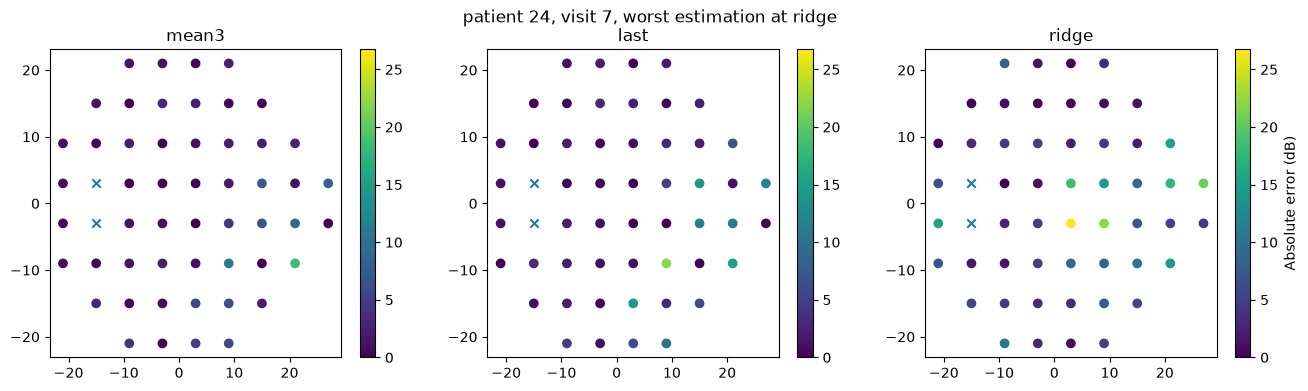

In [51]:
# 最も誤差が大きい人を抽出してその状態を解析
mae_worst = patient_mae[patient_mae["ridge"]==max(patient_mae["ridge"])]
print(mae_worst)
mask_worst = (meta[is_test]["id"]==mae_worst.index[0])

datas_worst_ridge = preds["ridge"][mask_worst]
print(datas_worst_ridge.shape)

datas_worst_mean_worst = np.abs(datas_worst_ridge - Y_test[mask_worst]).mean(axis=1)
print(datas_worst_mean_worst.shape)
visit_worst = np.where(datas_worst_mean_worst==datas_worst_mean_worst.max())
print(visit_worst)


print(preds["mean3"][mask_worst][visit_worst].shape)
print(Y_test[mask_worst][visit_worst].shape)
def calc_mae_1visit(single_data, y_single):
    return np.abs(single_data-y_single)

data_worttest_mean3 = calc_mae_1visit(preds["mean3"][mask_worst][visit_worst], Y_test[mask_worst][visit_worst])
data_worttest_last = calc_mae_1visit(preds["last"][mask_worst][visit_worst], Y_test[mask_worst][visit_worst])
data_worttest_ridge = calc_mae_1visit(datas_worst_ridge[visit_worst], Y_test[mask_worst][visit_worst])
# print(data_worttest_mean3.shape)

# 左目に左右反転
eye_side = meta[meta["id"] == mae_worst.index[0]]["eye"].unique()[0]
print(eye_side)
if eye_side == "OS":
    # print("warning!")
    l_x_pos_LR = np.array(l_x_pos)*-1
    l_x_pos_bs_LR = np.array(l_x_pos_bs)*-1
else:
    l_x_pos_LR = l_x_pos
    l_x_pos_bs_LR = l_x_pos_bs


fig, axes= plt.subplots(1,3, figsize=(16,4))

fig_max = max([data_worttest_mean3.max(), data_worttest_last.max(), data_worttest_ridge.max()])
fig_min = min([data_worttest_mean3.min(), data_worttest_last.min(), data_worttest_ridge.min()])

sc1 = axes[0].scatter(l_x_pos_LR, l_y_pos, c=data_worttest_mean3, vmax=fig_max, vmin=fig_min)
axes[0].set_title("mean3")
fig.colorbar(sc1, ax=axes[0])

axes[0].scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")

sc_2 = axes[1].scatter(l_x_pos_LR, l_y_pos, c=data_worttest_last, vmax=fig_max, vmin=fig_min)
fig.colorbar(sc_2, ax=axes[1])
axes[1].scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")
axes[1].set_title("last")

sc_ridge = axes[2].scatter(l_x_pos_LR, l_y_pos, c=data_worttest_ridge, vmax=fig_max, vmin=fig_min)
fig.colorbar(sc_ridge, ax=axes[2], label="Absolute error (dB)")
axes[2].scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")
axes[2].set_title("ridge")
# data_worttest_mean3



# plt.scatter(l_x_pos_LR, l_y_pos, c=data_worttest_mean3, vmax=data_max, vmin=data_min)
# plt.colorbar()
# plt.scatter(l_x_pos_bs_LR, l_y_pos_bs, marker="x")

# dir_save_fig = os.path.join(dir_save, f"{name_suffix}{name_base}.png")
# plt.savefig(dir_save_fig)
fig.suptitle(f"patient {mae_worst.index[0]}, visit {int(visit_worst[0])}, worst estimation at ridge")
plt.show()
# plt.close()


In [52]:
# print(np.sort(data_worttest_ridge)[0,-10:])
# print(np.argsort(data_worttest_ridge, axis=None))
# print([data_worttest_ridge[0,i] for i in np.argsort(data_worttest_ridge, axis=None)][-10:])

# 予測のずれた位置は変わっているのか？
print(np.argsort(data_worttest_mean3, axis=None)[::-1][:10])
print(np.argsort(data_worttest_last, axis=None)[::-1][:10])
print(np.argsort(data_worttest_ridge, axis=None)[::-1][:10])

[34 36 27 18 20 28 43 44 48 49]
[36 34 44 20 28 18 27 48 10 49]
[30 29 18 22 19 33 10 21 34 51]


0.24601466047222129
0.17879083278986838
0.01445266388344613


/tmp/ipykernel_16678/3356103988.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fig.suptitle(f"patient {mae_worst.index[0]}, visit {int(visit_worst[0])}")


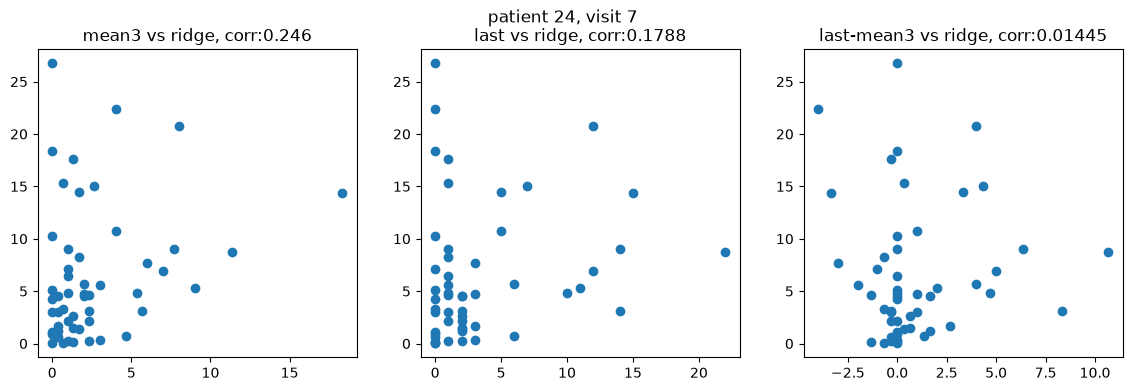

In [53]:
corr_ridge_mean3 = np.corrcoef(data_worttest_mean3, data_worttest_ridge)[0, 1]
print(corr_ridge_mean3)
corr_ridge_last = np.corrcoef(data_worttest_last, data_worttest_ridge)[0, 1]
print(corr_ridge_last)

corr_ridge_last_mean3 = np.corrcoef(data_worttest_last-data_worttest_mean3, data_worttest_ridge)[0, 1]
print(corr_ridge_last_mean3)

fig, axes = plt.subplots(1,3, figsize=(14,4))
axes[0].scatter(data_worttest_mean3, data_worttest_ridge)
axes[0].set_title("mean3 vs ridge, corr:{:.4}".format(corr_ridge_mean3))
axes[1].scatter(data_worttest_last, data_worttest_ridge)
axes[1].set_title("last vs ridge, corr:{:.4}".format(corr_ridge_last))
axes[2].scatter(data_worttest_last-data_worttest_mean3, data_worttest_ridge)
axes[2].set_title("last-mean3 vs ridge, corr:{:.4}".format(corr_ridge_last_mean3))
fig.suptitle(f"patient {mae_worst.index[0]}, visit {int(visit_worst[0])}")
plt.show()

In [54]:
X_test.shape

(81, 104)

In [55]:
dir_data =r"./data/vfpwgRetest24d2.csv"

df_data_check = pd.read_csv(dir_data)
df_data_check.head()

data_input = df_data_check[df_data_check["id"]==1][:3]
data_input

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,29,26,27,28,30,25,25,27,31
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,28,29,29,30,31,26,25,28,31
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,28,25,23,28,24,26,26,25


In [56]:
print(bs_pos)
l_points = [f"l{i+1}" for i in range(54) if not i in bs_pos]
print(l_points)
display(data_input[l_points].reset_index(drop=True))

[26. 35.]
['l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10', 'l11', 'l12', 'l13', 'l14', 'l15', 'l16', 'l17', 'l18', 'l19', 'l20', 'l21', 'l22', 'l23', 'l24', 'l25', 'l26', 'l28', 'l29', 'l30', 'l31', 'l32', 'l33', 'l34', 'l35', 'l37', 'l38', 'l39', 'l40', 'l41', 'l42', 'l43', 'l44', 'l45', 'l46', 'l47', 'l48', 'l49', 'l50', 'l51', 'l52', 'l53', 'l54']


,l1,l2,l3,l4,l5,l6,l7,l8,l9,l10,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,24,23,23,24,20,19,17,21,24,22,...,26,29,26,27,28,30,25,25,27,31
1,26,26,25,25,25,28,27,27,17,25,...,28,28,29,29,30,31,26,25,28,31
2,27,28,26,24,24,24,25,23,25,25,...,26,27,28,25,23,28,24,26,26,25


In [57]:
data_input_test = data_input.copy()
data_input_test["date"] = pd.to_datetime(data_input_test["date"])
data_input_test["date_change"] = data_input_test["date"].diff()
data_input_test

,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l46,l47,l48,l49,l50,l51,l52,l53,l54,date_change
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,29,26,27,28,30,25,25,27,31,NaT
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,29,29,30,31,26,25,28,31,7 days
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,27,28,25,23,28,24,26,26,25,7 days


In [58]:
import datetime

In [59]:
print(data_input_test["date_change"]<datetime.timedelta(days=0))

print((data_input_test["date"].diff()<datetime.timedelta(days=0)).sum())


((data_input[l_points]<0).sum().sum())>0

0    False
1    False
2    False
Name: date_change, dtype: bool
0


np.False_

In [60]:
import re


In [61]:
def predict_field_next_visit(input_field_3times_, method="ridge"):
    input_field_3times = input_field_3times_.copy()
    l_method = ["mean3", "last", "ridge"]
    if not method in l_method:
        raise ValueError('method must be last, mean3, or ridge')
    
    # 中身のチェックの前に欠損を調べるべき
    if input_field_3times.isnull().sum().sum(): 
        raise ValueError("there is lacked data")
    #各観測点のデータ型はint64なのでそもそもinfを取らない。データの値用なら非常識な値の範囲にしたほうがいいのかもしれない。
    if input_field_3times.isin([np.inf, -np.inf]).any().any(): 
        raise ValueError("there is inifinite data")
        
    if len(input_field_3times["eye"].unique())>1:
        raise ValueError('eye side is contaminated')
    if len(input_field_3times["id"].unique())>1:
        raise ValueError('patient id is contaminated')
    if len(input_field_3times.index)!=3:
        raise ValueError("invalid data length")
    

    
    
    input_field_3times["date_dt"]=pd.to_datetime(input_field_3times["date"])
    input_field_3times = input_field_3times.sort_values("date_dt")
    # sortするならなくてもいい?
    if (input_field_3times["date_dt"].diff()<datetime.timedelta(days=0)).sum(): 
        raise ValueError("date should be sourted by date")
    if not input_field_3times["date_dt"].is_monotonic_increasing:
        raise ValueError("date is not monotonicaly increased")
    
    
    if input_field_3times["date_dt"].duplicated().any():
        raise ValueError("date data is dulplicated")


    input_field_3times = input_field_3times.reset_index(drop=True)

    # 眼球データのカラム名が異なっていたらこれより後でエラー
    l_points = [f"l{i+1}" for i in range(54) if not i+1 in bs_pos]
    l_lack_point_label = [f"l{int(i)}" for i in bs_pos]
    # print(l_lack_point_label)
    l_points_in_data = [i_columns for i_columns in input_field_3times.columns if (not re.match(r"l\d{1,2}", i_columns) is None)and(not i_columns in l_lack_point_label)]
    # print(l_points)
    # print(l_points_in_data)
    if l_points!=l_points_in_data:
        raise ValueError("there is lacked point")

    # print(input_field_3times[l_points].isnull().sum(axis=1))
    # if input_field_3times[l_points].isnull().sum().sum(): # 欠損値は他のデータ部分の場合もあるので前段階で行うべき
    #     raise ValueError("there is lacked data")
    
    if len(input_field_3times[l_points].columns)!=52:
        raise ValueError("wrong data shape")
    
    if ((input_field_3times[l_points]<0).sum().sum())>0:
        raise ValueError("data point should be positive")

    mean3 = input_field_3times[l_points].mean(axis=0)
    # print(mean3.shape)
    change = input_field_3times[l_points].iloc[2] - mean3
    data_input = np.concatenate([mean3, change])
    # print(data_input.shape)

    if method=="ridge":
        prediction = search.predict([data_input])
    elif method=="mean3":
        prediction = mean3.to_numpy().reshape(1,-1)
    elif method=="last":
        prediction = input_field_3times[l_points].iloc[-1].to_numpy().reshape(1,-1)
    # print(prediction.shape)
    if prediction.shape != (1, 52):
        raise ValueError("wrong estimation")
    
    return {
        "id": input_field_3times["id"].unique()[0],
        "eye": input_field_3times["eye"].unique()[0],
        "age": input_field_3times["age"].unique()[0],
        "method": method,
        "data": prediction,
    }

predict_field_next_visit(data_input, method="ridge")

{'id': np.int64(1),
 'eye': 'OD',
 'age': np.int64(53),
 'method': 'ridge',
 'data': array([[23.2661604 , 22.12028087, 24.0827066 , 25.42769498, 23.86813851,
         24.32349862, 23.39725335, 21.32698758, 24.47970893, 23.97441064,
         20.61595141, 22.18731419, 16.4989581 , 21.08885702, 21.38297304,
         16.47779794, 24.57987973, 24.38061639, 12.96310991, 15.59519006,
         19.5015133 , 22.45172039, 27.78883386, 29.81847728, 27.61856335,
         27.29433702, 24.82395494, 26.87369152, 28.39189065, 29.27539824,
         30.71436869, 29.78254258, 29.50341298, 24.41727168, 26.20157618,
         29.69561545, 28.44778068, 29.01341271, 28.50942287, 27.36388791,
         27.43265986, 27.30081491, 27.00637093, 28.792576  , 28.85834428,
         26.57886476, 26.77876101, 27.31449433, 26.58351231, 24.14630889,
         26.97851621, 28.81268929]])}

In [62]:
data_row = df_data_check[df_data_check["id"].isin(X_test_id)]
l_method = ["mean3", "last", "ridge"]

l_resullts = []
for i_method in l_method:
    for i_id in data_row["id"].unique():
        data_sliced  = data_row[data_row["id"]==i_id]

        # sliding-window
        for i in range(3,len(data_sliced)):
            # display()
            l_resullts.append(predict_field_next_visit(data_sliced.iloc[i-3:i], method=i_method))

In [63]:
np_result_last = np.array([i["data"][0] for i in l_resullts if i["method"]=="last"])
print(np_result_last.shape)
print(preds["last"].shape)
print(np_result_last==preds["last"])

(81, 52)
(81, 52)
[[ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 ...
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]
 [ True  True  True ...  True  True  True]]


In [64]:
print(type(preds["last"]))

<class 'numpy.ndarray'>


In [65]:
# 一致テスト
for i_method in l_method:
    np_result_method = np.array([i["data"][0] for i in l_resullts if i["method"]==i_method])
    preds_method = preds[i_method]
    # match_test = np_result_last==preds[i_method]
    # print(i_method, match_test.all())

    # chatgpt: 許容範囲アリの判定
    np.testing.assert_allclose(
        np_result_method,
        preds_method,
        rtol=1e-7,
        atol=1e-8
    )
    print(f"PASS: {i_method}")
    

PASS: mean3
PASS: last
PASS: ridge


In [66]:
# 異常系テスト
display(data_input)

def fail_test(data, method="ridge"):
    try:
        result = predict_field_next_visit(data, method=method)
        # return result
    except ValueError as e:
        print(e)
        # return None
    else:
        raise AssertionError("FAIL: ValueErrorが発生しませんでした。")

# method
fail_test(data_input, method="fuhgsiuk")


# data lack
data_input_lack = data_input.copy()
data_input_lack.loc[1, "date"] = np.nan
fail_test(data_input_lack, method="ridge")

# data inf
data_input_inf = data_input.copy()
data_input_inf.loc[1, "fl"] = np.inf
fail_test(data_input_inf, method="ridge")


# eye
data_input_eye = data_input.copy()
data_input_eye.loc[1, "eye"] = "OS"
fail_test(data_input_eye, method="ridge")


# id
data_input_id = data_input.copy()
data_input_id.loc[1, "id"] = 2
fail_test(data_input_id, method="ridge")


# date duplicated
data_input_dup = data_input.copy()
data_input_dup.loc[1, "date"] = data_input_dup.loc[2, "date"]
fail_test(data_input_dup, method="ridge")

# negative data
data_input_neg = data_input.copy()
data_input_neg.loc[1, "l46"] = -1
fail_test(data_input_neg, method="ridge")

# data length
data_input_2 = data_input.iloc[:2]
fail_test(data_input_2, method="ridge")

# date 
data_input_date = data_input.copy()
data_input_date.loc[1, "date"] = data_input_date.loc[0, "date"]
fail_test(data_input_date, method="ridge")



# data point lack
data_input_plack = data_input.copy()
data_input_plack = data_input_plack.drop(["l46"], axis=1)
fail_test(data_input_plack, method="ridge")


,id,eye,date,time,age,type,fpr,fnr,fl,duration,...,l45,l46,l47,l48,l49,l50,l51,l52,l53,l54
0,1,OD,2008-08-13,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,29,26,27,28,30,25,25,27,31
1,1,OD,2008-08-20,00:00:00,53,pwg,0,0.0,0.06,00:00:00,...,28,28,29,29,30,31,26,25,28,31
2,1,OD,2008-08-27,00:00:00,53,pwg,0,0.0,0.00,00:00:00,...,26,27,28,25,23,28,24,26,26,25


method must be last, mean3, or ridge
there is lacked data
there is inifinite data
eye side is contaminated
patient id is contaminated
date data is dulplicated
data point should be positive
invalid data length
date data is dulplicated
there is lacked point


In [67]:
# date not sorted
data_input_sorted = data_input.copy()
data_input_sorted.loc[3] = data_input_sorted.loc[2]
data_input_sorted.loc[2] = data_input_sorted.loc[1]
data_input_sorted.loc[1] = data_input_sorted.loc[3]
data_input_sorted = data_input_sorted.drop(3)
# display(data_input_sorted)
# display(pd.to_datetime(data_input_sorted["date"]).diff()<datetime.timedelta(0))
# sortするなら失敗しない
result_presort = predict_field_next_visit(data_input.copy(), method="last")
result_sorted = predict_field_next_visit(data_input_sorted, method="last")
# print(result_presort)
# print(result_sorted)
np.testing.assert_allclose(
    result_presort["data"], 
    result_sorted["data"],
    rtol=1e-7,
    atol=1e-8,
)
print("sorted test is passed")

data_input_processed = data_input.copy()
result_presort = predict_field_next_visit(data_input_processed, method="mean3")
pd.testing.assert_frame_equal(
    data_input_processed,
    data_input,
)
print("processed data is protected")

sorted test is passed
processed data is protected


In [79]:
# 全データを用いてリッジ回帰
# print(history.reshape(270, 156)[0] == history[0].reshape(1,156))
X_all = history.reshape(270, 156)
X_all_train = X_all[is_train]
X_all_test = X_all[is_test]

model_grid_all = make_pipeline(
    StandardScaler(),
    Ridge()
)
lambdas = np.logspace(-4, 4, 50)

search_all = GridSearchCV(
    model_grid_all,
    param_grid={"ridge__alpha":lambdas},
    cv=GroupKFold(n_splits=5),
    scoring="neg_mean_squared_error",
)

training_group_all = meta.loc[is_train, "id"].to_numpy()
display(training_group_all)

search_all.fit(X_all_train, Y_train, groups=training_group_all)

print("最適なα: ", search_all.best_params_)
print("λ: ", search.best_params_["ridge__alpha"]/X_all_test.shape[1])

prediction_grid_all = search_all.predict(X_all_test)



array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,
        4,  4,  5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,
        6,  6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8, 11, 11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12,
       12, 12, 12, 12, 12, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 17, 17, 17, 17, 17, 17, 17, 17, 17, 19, 19,
       19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20, 20, 20, 20, 20, 20, 21,
       21, 21, 21, 21, 21, 21, 21, 21, 22, 22, 22, 22, 22, 22, 22, 22, 22,
       23, 23, 23, 23, 23, 23, 23, 23, 23, 26, 26, 26, 26, 26, 26, 26, 26,
       26, 27, 27, 27, 27, 27, 27, 27, 27, 27, 30, 30, 30, 30, 30, 30, 30,
       30, 30])

最適なα:  {'ridge__alpha': np.float64(232.99518105153672)}
λ:  1.025550461285934


In [80]:
X_all_train.shape

(189, 156)

In [91]:
from sklearn import linear_model

model_liner_all = linear_model.LinearRegression()
model_liner_all.fit(X_all_train, Y_train)
prediction_linear_all = model_liner_all.predict(X_all_test)

model_liner = linear_model.LinearRegression()
model_liner.fit(X_train, Y_train)
prediction_linear = model_liner.predict(X_test)
# print(prediction_linear)

In [105]:
preds = {
    "last":last[is_test],
    "mean3":mean3[is_test],
    "ridge":prediction_grid,
    "ridge_single":prediction,
    "rideg_all":prediction_grid_all,
    "linear":prediction_linear,
    "linear_all":prediction_linear_all,
}

# 全予測値のうち負の値のデータ点
d_negative = {name: (pred_each<0).sum() for name, pred_each in preds.items()}
df_negative = pd.DataFrame(d_negative, index=["negative"])

# テストデータ全体と予測値間のMAE
# 全体でのMAEは大して改善しなかった
d_mae = {name: np.abs(pred_each - Y_test).mean() for name, pred_each in preds.items()}
df_mae = pd.DataFrame(d_mae, index=["MAR (all)"])

df_result = pd.concat([df_negative, df_mae])
display(df_result.style.format("{:.2f}"))




,last,mean3,ridge,ridge_single,rideg_all,linear,linear_all
negative,0.00,0.00,1.00,63.00,5.00,71.00,177.00
MAR (all),2.10,1.78,2.81,6.09,2.78,6.31,8.73


In [ ]:
fig = plt.figure(figsize=(12,6))
axes = fig.subplots(1,2)
metrics["patient_macro_MAE_dB"].plot.bar(ax=axes[0])
axes[0].set_ylabel("patien-maco MAE (dB)")
# axes[0].set_xlabel("Held-out patient ID")
axes[0].set_title("Lower is close to the next mesurement")
patient_mae.plot(ax=axes[1], marker="o")
axes[1].set_ylabel("MAE (dB)")
axes[1].set_xlabel("Held-out patient ID")
axes[1].set_title("HVariant between patients")
plt.plot()